# Activity: Should We Trust the Alarm? — FreshKart Cold-Chain Case

**Unit 4 · AI-Assisted Visualization · AI-Assisted Pattern and Anomaly Visualization**
Visualization of Data, Understanding and Interpretation (UE24CS342AA9)

---

## The case

FreshKart's dark stores keep frozen food in **8 freezers** (one per store in Bengaluru, Pune and Hyderabad). Each freezer reports its temperature every hour. Last month FreshKart bought **ColdSense**, an AI service that scores every reading for "anomaly" and raises an alert when the score is **≥ 0.5**.

Cold-chain lead **Ravi** has six weeks of readings, the ColdSense scores, and the **maintenance log** (what technicians actually found). His technicians are tired of being sent out at night. He asks:

> *"Is ColdSense's alert feed trustworthy? Which alerts should my team chase, and what is it missing?"*

**You are the analyst.** Use the data and the visualizations to verify, correct or reject what the vendor claims.

**Ground rules (from the lecture):** an AI score is a *derived attribute*: look at it, don't only threshold it · flags are **candidates, not conclusions** · report precision and recall, not accuracy · scale emphasis to confidence.

**How to work:** run the notebook top to bottom. Complete every cell marked `# TODO` (replace `None` with your code or answer) and write in the cells marked **✏️ Your answer**. Cells that depend on your TODO will tell you if something is still missing.

### The data: `freshkart_coldchain.csv` (synthetic)

| Column | Meaning |
|---|---|
| `timestamp` | hour of the reading (1 Aug – 11 Sep 2026) |
| `city`, `store_id`, `freezer_id` | where the freezer is |
| `temp_c` | freezer temperature (°C); normal is about −18 °C |
| `door_opens` | number of door openings in that hour (busy by day, quiet at night) |
| `compressor_kw` | compressor power draw (kW) |
| `ai_score`, `ai_flag` | ColdSense anomaly score (0–1) and alert (1 if score ≥ 0.5) |
| `confirmed_fault`, `fault_type` | from the maintenance log: 1 if technicians confirmed a real fault in that hour, and what it was |

**Domain note from the maintenance team:** every freezer runs an automatic **defrost cycle from 02:00 to 04:00** each night. The heater warms the coil, so the temperature rises for those two hours. That is normal.

In [20]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.figsize": (6, 3.2), "axes.spines.top": False, "axes.spines.right": False})
GREY, ACCENT, BLUE = "#bdbdbd", "#d95f02", "#4c78a8"

def ready(*vals):
    """Helper: tells you if a TODO above is still unanswered."""
    ok = all(v is not None for v in vals)
    if not ok:
        print("⚠ Complete the TODO cell(s) above first, then re-run this cell.")
    return ok

df = pd.read_csv("freshkart_coldchain.csv", parse_dates=["timestamp"])
df["hour"] = df["timestamp"].dt.hour
df.head()

,timestamp,city,store_id,freezer_id,temp_c,door_opens,compressor_kw,ai_score,ai_flag,confirmed_fault,fault_type,hour
0,2026-08-01,Bengaluru,B1,FZ-B1,-18.1,0,1.29,0.000,0,0,NaN,0
1,2026-08-01,Bengaluru,B2,FZ-B2,-18.7,0,1.16,0.000,0,0,NaN,0
2,2026-08-01,Bengaluru,B3,FZ-B3,-17.7,0,1.21,0.000,0,0,NaN,0
3,2026-08-01,Hyderabad,H1,FZ-H1,-17.8,0,1.30,0.037,0,0,NaN,0
4,2026-08-01,Hyderabad,H2,FZ-H2,-18.2,0,1.32,0.035,0,0,NaN,0


## ColdSense's monthly report (to be validated)

| # | Vendor statement |
|---|---|
| 1 | "ColdSense is **97.9% accurate**, so its alerts can be trusted." |
| 2 | "**Most faults happen around 2 am.** We recommend a night technician." |
| 3 | "**All 10 compressor trips** in the period were caught." |
| 4 | "Freezer **FZ-H2 ran without a single fault** in August." |
| 5 | "A reading of **−14 °C is abnormal** for any freezer, at any time." |
| 6 | "An alert with a score of **0.92 means a 92% chance** of a real fault." |
| 7 | "The **default threshold of 0.5** is the best setting for FreshKart." |
| 8 | "A new FZ-B1 reading of **−15.9 °C at 14:00** is **15 standard errors** above normal: a definite fault." |

---
## Part 1 · Data abstraction: items, attributes and derived attributes

Munzner: before choosing a view, ask what the **items** and **attributes** are. The AI does not change the items; it **derives** new attributes.

In [21]:
derived_cols = ["hour", "ai_score", "ai_flag"]
n_alerts = int((df["ai_flag"] == 1).sum())
fault_rate_pct = round(df["confirmed_fault"].mean() * 100, 2)

if ready(derived_cols, n_alerts, fault_rate_pct):
    print(f"derived: {derived_cols} | alerts: {n_alerts} | faults: {df.confirmed_fault.sum()} of {len(df)} rows ({fault_rate_pct}%)")
    display(df[df.confirmed_fault == 1].groupby("fault_type").size().rename("fault hours"))

derived: ['hour', 'ai_score', 'ai_flag'] | alerts: 159 | faults: 46 of 8064 rows (0.57%)


fault_type
compressor trip         10
defrost heater stuck    11
sensor frozen           25
Name: fault hours, dtype: int64

**✏️ Your answer (Part 1):** `ai_score` is quantitative and `ai_flag` is binary. Which **visual channel** suits each, and what information does the flag throw away that the score keeps?

*Your answer:*The ai_score is quantitative, so colour intensity or position on a continuous scale is suitable for representing its value. The ai_flag is binary, so a distinct colour or symbol can represent whether an alert was raised. However, the flag throws away the confidence information contained in the score because it only tells us whether the score crossed the threshold of 0.5.

---
## Part 2 · Distributions: bin width and the score distribution

### 2a · Temperature histogram

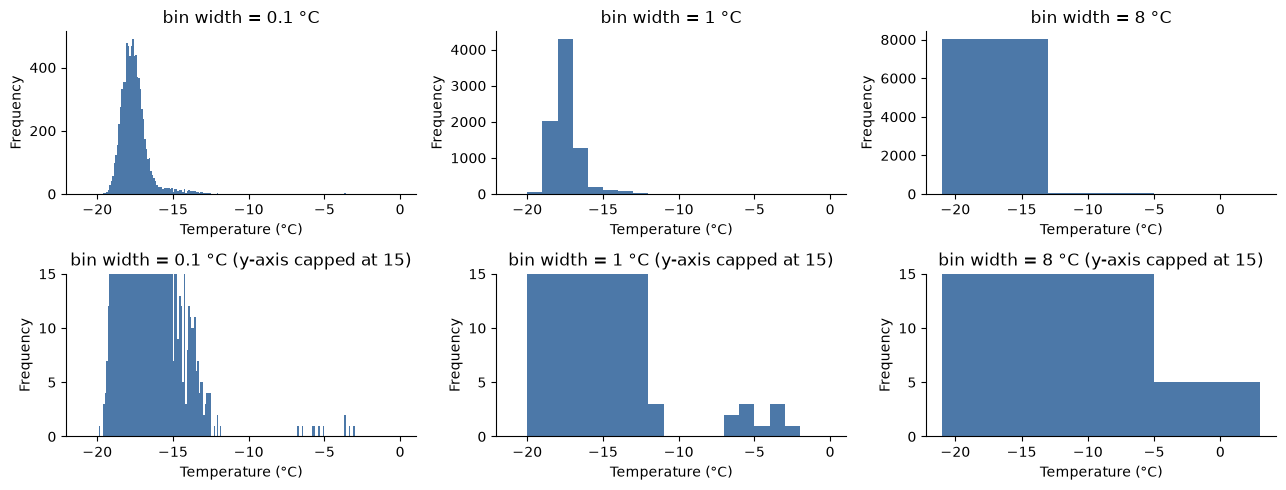

In [22]:
fig, axes = plt.subplots(2, 3, figsize=(13, 5))

for col, w in enumerate([0.1, 1, 8]):
    for row, top in enumerate([None, 15]):
        ax = axes[row, col]

        ax.hist(
            df["temp_c"],
            bins=np.arange(-21, 0 + w, w),
            color=BLUE
        )

        if top:
            ax.set_ylim(0, top)
            ax.set_title(f"bin width = {w} °C (y-axis capped at 15)")
        else:
            ax.set_title(f"bin width = {w} °C")

        ax.set_xlabel("Temperature (°C)")
        ax.set_ylabel("Frequency")

plt.tight_layout()
plt.show()

### 2b · Look at the AI scores before trusting the cut-off
Wilke: compare groups with overlapping densities, not stacked histograms.

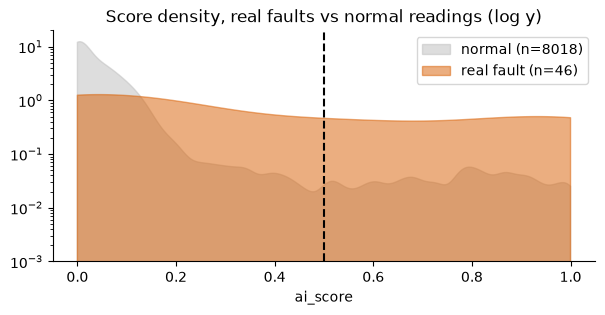

In [23]:
xs = np.linspace(0, 1, 300)
fig, ax = plt.subplots(figsize=(7, 3))
for lab, col in [(0, GREY), (1, ACCENT)]:
    s = df.loc[df.confirmed_fault == lab, "ai_score"]
    ax.fill_between(xs, stats.gaussian_kde(s)(xs), color=col, alpha=.5, label=f"{'real fault' if lab else 'normal'} (n={len(s)})")
ax.axvline(0.5, color="k", ls="--"); ax.set_yscale("log"); ax.set_ylim(1e-3, 20)
ax.set_xlabel("ai_score"); ax.legend(); ax.set_title("Score density, real faults vs normal readings (log y)")
plt.show()

normal_scores = df.loc[df["confirmed_fault"] == 0, "ai_score"]
fault_scores = df.loc[df["confirmed_fault"] == 1, "ai_score"]

scores_separate_faults = (
    fault_scores.min() > normal_scores.max()
    or normal_scores.min() > fault_scores.max()
)

**✏️ Your answer (Part 2):** Why is a histogram "a parameterised algorithm", and what would you tell a colleague who says *"the 8 °C histogram shows no anomalies"*?

*Your answer:*A histogram is a parameterised algorithm because its appearance depends on choices such as bin width and bin boundaries. An 8 °C bin width combines many different temperature readings into broad groups, hiding smaller patterns and unusual readings. I would recommend checking narrower bin widths and the underlying data before concluding that there are no anomalies.

---
## Part 3 · Outlier rules on a short window (vendor statement 3)

Ten consecutive readings from **FZ-P1**, 12 Aug 06:00–15:00. One of them is a compressor trip.

In [24]:
window = df[(df.freezer_id == "FZ-P1") & (df.timestamp >= "2026-08-12 06:00") & (df.timestamp < "2026-08-12 16:00")]
v = window["temp_c"].values
print(window[["timestamp", "temp_c", "fault_type"]].to_string(index=False))

z_max = np.max(np.abs((v - np.mean(v)) / np.std(v, ddof=1)))
q1, q3 = np.percentile(v, [25, 75])
upper_fence = q3 + 1.5 * (q3 - q1)

if ready(z_max, upper_fence):
    print(f"largest |z| = {z_max:.2f} -> flagged by |z| > 3? {z_max > 3}")
    print(f"upper IQR fence = {upper_fence:.2f} °C -> trip flagged by IQR rule? {v.max() > upper_fence}")
    print(f"largest |z| possible with n = {len(v)}: {(len(v) - 1) / np.sqrt(len(v)):.2f}")

          timestamp  temp_c      fault_type
2026-08-12 06:00:00   -17.5             NaN
2026-08-12 07:00:00   -18.2             NaN
2026-08-12 08:00:00   -17.4             NaN
2026-08-12 09:00:00   -17.7             NaN
2026-08-12 10:00:00   -16.6             NaN
2026-08-12 11:00:00    -3.6 compressor trip
2026-08-12 12:00:00   -17.0             NaN
2026-08-12 13:00:00   -16.8             NaN
2026-08-12 14:00:00   -17.7             NaN
2026-08-12 15:00:00   -17.7             NaN
largest |z| = 2.83 -> flagged by |z| > 3? False
upper IQR fence = -15.58 °C -> trip flagged by IQR rule? True
largest |z| possible with n = 10: 2.85


**✏️ Your answer (Part 3):** Explain in two sentences why the z-score rule missed the trip here (use the word *masking*) and why the IQR rule did not.

*Your answer:*The z-score rule missed the compressor trip because the extreme reading influenced the mean and standard deviation, causing masking; its maximum absolute z-score was approximately 2.83, below the threshold of 3. The IQR rule detected it because the trip temperature of −3.6 °C was far above the upper fence of approximately −15.58 °C.

---
## Part 4 · How good is ColdSense? (vendor statement 1)

In [25]:
flag = df.ai_flag == 1
real = df.confirmed_fault == 1
TP = int((flag & real).sum())
FP = int((flag & ~real).sum())
FN = int((~flag & real).sum())
TN = int((~flag & ~real).sum())

if ready(TP, FP, FN, TN):
    display(pd.DataFrame([[TP, FN], [FP, TN]], index=["real fault", "normal"], columns=["alert", "no alert"]))

,alert,no alert
real fault,16,30
normal,143,7875


In [26]:
precision = TP / (TP + FP) if (TP + FP) else 0
recall = TP / (TP + FN) if (TP + FN) else 0
f1 = 2 * precision * recall / (precision + recall) if (precision + recall) else 0
accuracy = (TP + TN) / len(df)
flag_nothing_accuracy = (df["confirmed_fault"] == 0).mean()

if ready(precision, recall, f1, accuracy, flag_nothing_accuracy):
    print(f"precision = {precision:.2f} | recall = {recall:.2f} | F1 = {f1:.2f} | accuracy = {accuracy:.1%} | never-alert accuracy = {flag_nothing_accuracy:.1%}")

precision = 0.10 | recall = 0.35 | F1 = 0.16 | accuracy = 97.9% | never-alert accuracy = 99.4%


**✏️ Your answer (Part 4):** Rewrite vendor statement 1 so it is honest. Use precision and recall, and say in plain words what they mean for Ravi's technicians (how many call-outs are wasted, how many faults are missed).

*Your answer:*Although ColdSense has approximately 97.9% accuracy, its precision is only 10.1% and its recall is 34.8%. This means that only about 1 in 10 alerts corresponds to a confirmed fault, so approximately 9 in 10 call-outs may be unnecessary, while the system misses approximately 65.2% of actual faults. Therefore, accuracy alone does not prove that the alert system is trustworthy.

---
## Part 5 · Thresholds and costs (vendor statement 7)

A missed fault can spoil a freezer of stock (cost ≈ **40** units); a false call-out costs **1** unit of technician time.

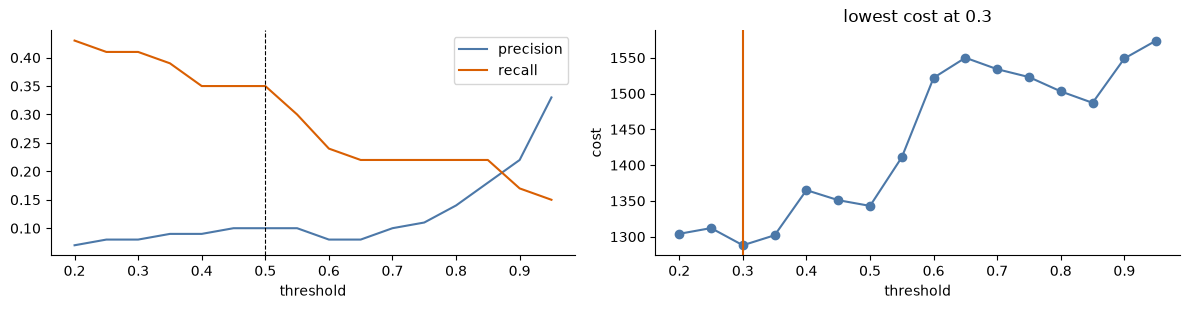

,threshold,TP,FP,FN,precision,recall,cost
0,0.20,20,264,26,0.07,0.43,1304
1,0.25,19,232,27,0.08,0.41,1312
2,0.30,19,208,27,0.08,0.41,1288
3,0.35,18,182,28,0.09,0.39,1302
4,0.40,16,165,30,0.09,0.35,1365
5,0.45,16,151,30,0.10,0.35,1351
6,0.50,16,143,30,0.10,0.35,1343
7,0.55,14,131,32,0.10,0.30,1411
8,0.60,11,122,35,0.08,0.24,1522
9,0.65,10,110,36,0.08,0.22,1550


In [27]:
grid = np.round(np.arange(0.20, 0.96, 0.05), 2)
sweep = pd.DataFrame({"threshold": grid})
sweep["TP"] = [((df.ai_score >= g) & real).sum() for g in grid]
sweep["FP"] = [((df.ai_score >= g) & ~real).sum() for g in grid]
sweep["FN"] = real.sum() - sweep["TP"]
sweep["precision"] = (sweep.TP / (sweep.TP + sweep.FP)).round(2)
sweep["recall"] = (sweep.TP / real.sum()).round(2)

sweep["cost"] = 40 * sweep["FN"] + sweep["FP"]
best_threshold = float(sweep.loc[sweep["cost"].idxmin(), "threshold"])

if ready(best_threshold) and sweep["cost"].notna().all():
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.2))
    ax[0].plot(sweep.threshold, sweep.precision, color=BLUE, label="precision"); ax[0].plot(sweep.threshold, sweep.recall, color=ACCENT, label="recall")
    ax[0].axvline(0.5, color="k", ls="--", lw=.8); ax[0].legend(); ax[0].set_xlabel("threshold")
    ax[1].plot(sweep.threshold, sweep.cost.astype(float), color=BLUE, marker="o"); ax[1].axvline(best_threshold, color=ACCENT)
    ax[1].set_xlabel("threshold"); ax[1].set_ylabel("cost"); ax[1].set_title(f"lowest cost at {best_threshold}")
    plt.tight_layout(); plt.show()
    display(sweep)

**✏️ Your answer (Part 5):** Even at the best threshold, recall stays low. Why can no threshold fix this detector? (Hint: look at *which* faults are never scored high.)

*Your answer:*The detector struggles because it assigns very low anomaly scores to sensor-frozen faults. All 25 sensor-frozen fault readings have scores below 0.1, so changing the threshold cannot detect them reliably. The detector needs a different approach that can identify patterns such as a sensor reporting exactly the same temperature repeatedly.

---
## Part 6 · Where do the errors come from?

### 6a · When do the false alarms happen? (vendor statement 2)

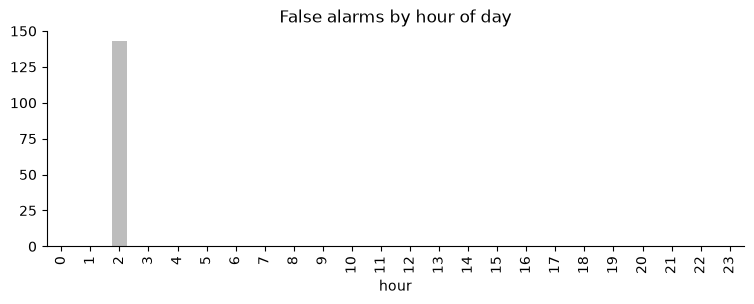

100% of false alarms happen at 2:00


In [28]:
fp_rows = df[flag & ~real]
fp_rows.groupby("hour").size().reindex(range(24), fill_value=0).plot.bar(color=GREY, title="False alarms by hour of day", figsize=(9, 2.8))
plt.show()

fp_by_hour = fp_rows.groupby("hour").size().reindex(range(24), fill_value=0)
fp_peak_hour = int(fp_by_hour.idxmax())
fp_share_at_peak = float(fp_by_hour.max() / len(fp_rows))

if ready(fp_peak_hour, fp_share_at_peak):
    print(f"{fp_share_at_peak:.0%} of false alarms happen at {fp_peak_hour}:00")

### 6b · Which faults does ColdSense miss?

In [29]:
caught = df[real].groupby("fault_type")["ai_flag"].agg(caught="sum", fault_hours="size")
caught["recall"] = (caught.caught / caught.fault_hours).round(2)
display(caught)
never_caught_type = caught.loc[caught["caught"] == 0].index.tolist()
anomaly_kind = "collective"

,caught,fault_hours,recall
fault_type,,,
compressor trip,10,10,1.00
defrost heater stuck,6,11,0.55
sensor frozen,0,25,0.00


### 6c · Contextual anomalies: compare each reading with its own hour

A **context-aware** baseline compares each reading with the same freezer at the same hour of day (median and MAD over the six weeks).

In [30]:
grp = df.groupby(["freezer_id", "hour"])["temp_c"]
df["hour_median"] = grp.transform("median")
df["hour_mad"] = grp.transform(lambda s: 1.4826 * stats.median_abs_deviation(s))

df["z_context"] = (df["temp_c"] - df["hour_median"]) / df["hour_mad"].replace(0, np.nan)

if ready(*df["z_context"].head(1)):
    ctx_flag = df["z_context"].astype(float) > 4
    found = df[real & ctx_flag & ~flag]
    print(f"Real faults the context baseline catches but ColdSense missed: {len(found)}")
    display(found[["timestamp", "freezer_id", "temp_c", "hour_median", "z_context", "ai_score", "fault_type"]])
    print(f"False alarms at 02:00 under the context baseline: {(ctx_flag & ~real & (df.hour == 2)).sum()} (ColdSense: {(flag & ~real & (df.hour == 2)).sum()})")

Real faults the context baseline catches but ColdSense missed: 3


,timestamp,freezer_id,temp_c,hour_median,z_context,ai_score,fault_type
1279,2026-08-07 15:00:00,FZ-P2,-14.6,-17.50,4.890058,0.369,defrost heater stuck
4731,2026-08-25 15:00:00,FZ-H1,-14.8,-17.50,6.070417,0.388,defrost heater stuck
6273,2026-09-02 16:00:00,FZ-B2,-15.2,-17.35,4.143300,0.189,defrost heater stuck


False alarms at 02:00 under the context baseline: 0 (ColdSense: 143)


### 6d · Collective anomalies: a run of readings that is abnormal together

                           min                 max  count
freezer_id                                               
FZ-H2      2026-08-20 14:00:00 2026-08-20 22:00:00      9
FZ-P1      2026-09-06 12:00:00 2026-09-06 17:00:00      6


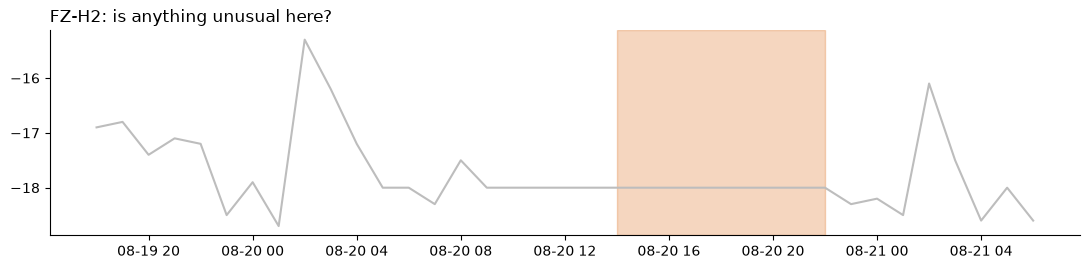

In [31]:
df = df.sort_values(["freezer_id", "timestamp"])
df["roll_sd_6h"] = df.groupby("freezer_id")["temp_c"].transform(lambda s: s.rolling(6).std())

flat = df[df["roll_sd_6h"] < 0.01].copy()

if ready(flat):
    print(flat.groupby("freezer_id")["timestamp"].agg(["min", "max", "count"]))
    h2 = df[(df.freezer_id == "FZ-H2") & (df.timestamp.between("2026-08-19 18:00", "2026-08-21 06:00"))]
    fig, ax = plt.subplots(figsize=(11, 2.8))
    ax.plot(h2.timestamp, h2.temp_c, color=GREY)
flat_h2 = flat[
    (flat["freezer_id"] == "FZ-H2") &
    (flat["timestamp"].between(
        "2026-08-19 18:00",
        "2026-08-21 06:00"
    ))
]
if not flat_h2.empty:
    ax.axvspan(
        flat_h2["timestamp"].min(),
        flat_h2["timestamp"].max(),
        color=ACCENT,
        alpha=0.25
    )

ax.set_title("FZ-H2: is anything unusual here?", loc="left")
plt.tight_layout()
plt.show()

**✏️ Your answer (Part 6):**
 
(a) Rewrite vendor statement 2. What really happens at 2 am, and what would happen if FreshKart hired a night technician based on the vendor's report?

At 2 am, the freezers undergo their normal automatic defrost cycle, which causes temperatures to rise temporarily. The AI generates 143 false alarms at 2 am, while there are no confirmed faults at that hour. Hiring a night technician based on this report would waste technician time and resources.

(b) Is vendor statement 5 true? Use the words contextual anomaly and say what a chart must show for a viewer to judge such an alert.

No, a temperature of −14 °C is not automatically abnormal for every freezer at every time. It may be normal during the automatic defrost cycle, but it could be a contextual anomaly at another time. A chart should show the temperature over time along with the freezer's normal temperature range and the time of day so that viewers can judge the reading in context.

(c) What is wrong with vendor statement 4, and why can a detector that scores readings one at a time never catch this kind of fault?

Vendor statement 4 is incorrect because freezer FZ-H2 experienced a sensor-frozen fault on 20 August, with 14 consecutive readings remaining at −18 °C. A detector that evaluates individual readings may consider each temperature normal, but it can miss the collective anomaly because the problem is visible only when the repeated readings are examined together over time.


---
## Part 7 · Highlighting, saliency and frequency framing (vendor statement 6)

### 7a · Emphasis scaled to confidence
The vendor's dashboard paints every alert bright red. Implement the lecture's checklist: **≥ 0.90 strong**, **0.70–0.90 moderate**, **0.50–0.70 subtle outline**, **below 0.50 no emphasis** (the data stays visible).

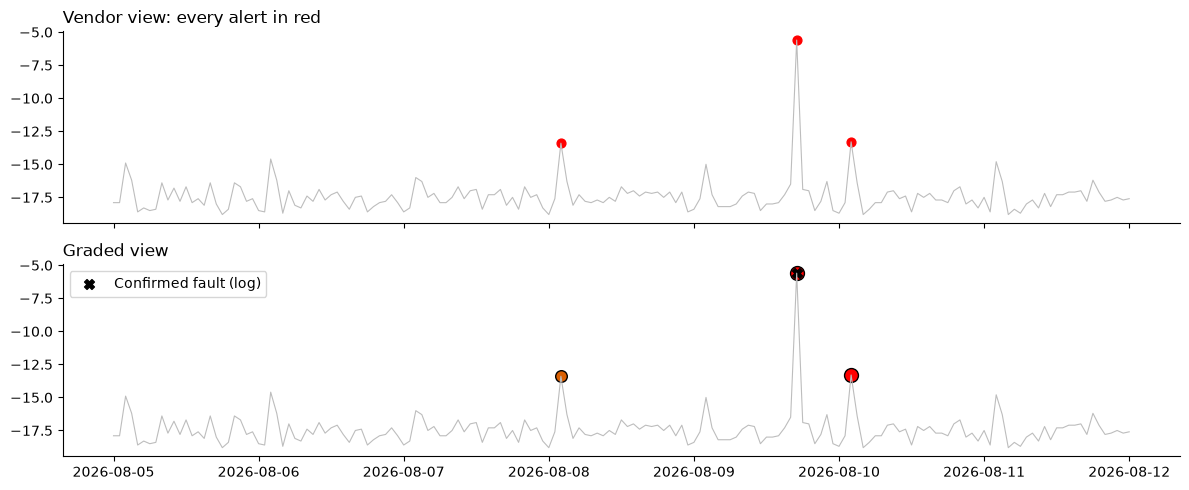

In [32]:
def emphasis(score):
    """Return (colour, marker size, edge colour) for one reading."""

    if score >= 0.90:
        return "red", 100, "black"
    elif score >= 0.70:
        return ACCENT, 70, "black"
    elif score >= 0.50:
        return BLUE, 45, "black"
    else:
        return GREY, 20, "none"


week = df[
    (df.freezer_id == "FZ-B2") &
    (df.timestamp.between("2026-08-05", "2026-08-12"))
]

fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)

# Vendor view: every AI alert is shown in red
ax[0].plot(week.timestamp, week.temp_c, color=GREY, lw=0.8)

a = week[week.ai_flag == 1]

ax[0].scatter(
    a.timestamp,
    a.temp_c,
    color="red",
    s=40
)

ax[0].set_title(
    "Vendor view: every alert in red",
    loc="left"
)

# Graded view: emphasis depends on AI confidence
ax[1].plot(week.timestamp, week.temp_c, color=GREY, lw=0.8)

for _, r in week[week.ai_score >= 0.5].iterrows():
    col, size, edge = emphasis(r.ai_score)

    ax[1].scatter(
        r.timestamp,
        r.temp_c,
        color=col,
        s=size,
        edgecolors=edge
    )

# Confirmed faults shown with X markers
f = week[week.confirmed_fault == 1]

ax[1].scatter(
    f.timestamp,
    f.temp_c,
    marker="X",
    color="black",
    s=50,
    label="Confirmed fault (log)"
)

ax[1].legend(loc="upper left")
ax[1].set_title("Graded view", loc="left")

plt.tight_layout()
plt.show()

### 7b · "A score of 0.92 means 92%"? Count it.
Wilke: people read probabilities better as **frequencies**. Of all alerts in a score band, how many were real?

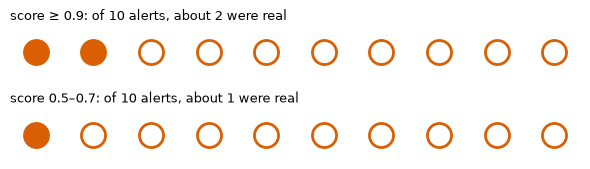

In [33]:
band_hi = df[df.ai_score >= 0.9]
band_lo = df[(df.ai_score >= 0.5) & (df.ai_score < 0.7)]

real_per_10_hi = round(band_hi["confirmed_fault"].mean() * 10)
real_per_10_lo = round(band_lo["confirmed_fault"].mean() * 10)

if ready(real_per_10_hi, real_per_10_lo):
    fig, ax = plt.subplots(2, 1, figsize=(6, 1.8))
    for a_, k, lab in zip(ax, [real_per_10_hi, real_per_10_lo], ["score ≥ 0.9", "score 0.5–0.7"]):
        for i in range(10): a_.scatter(i, 0, s=300, color=ACCENT if i < k else "white", edgecolors=ACCENT, linewidths=2)
        a_.axis("off"); a_.set_title(f"{lab}: of 10 alerts, about {k} were real", loc="left", fontsize=9)
    plt.tight_layout(); plt.show()

**✏️ Your answer (Part 7):** 
(a) Why does a red dot at every alert make Ravi's team more likely to miss the frozen H2 sensor? Use the words salience and inattentional blindness.

When every alert is displayed in bright red, all alerts receive the same visual salience, regardless of their confidence or importance. This creates visual clutter and can cause inattentional blindness, making technicians overlook important patterns such as the repeated −18 °C readings from freezer H2. Using different levels of emphasis would help technicians focus on the most important alerts.

(b) Rewrite vendor statement 6 using frequency framing.

An AI score of 0.92 does not mean there is a 92% chance of a real fault. In this dataset, among readings with scores of at least 0.90, approximately 8 out of 37 were confirmed faults. This is a frequency of about 22%, not 92%.

---
## Part 8 · Standard deviation vs standard error (vendor statement 8)

The vendor judged a new FZ-B1 reading of **−15.9 °C at 14:00** against the 14:00 baseline.

In [34]:
base = df[(df.freezer_id == "FZ-B1") & (df.hour == 14) & (df.confirmed_fault == 0)]["temp_c"]
mu, sd, n = base.mean(), base.std(), len(base)
new_reading = -15.9

se = sd / np.sqrt(n)
z_sd = (new_reading - mu) / sd
z_se = (new_reading - mu) / se

if ready(se, z_sd, z_se):
    print(f"baseline: mean {mu:.2f} °C, SD {sd:.2f}, n = {n}, SE = {se:.3f}")
    print(f"z using SD = {z_sd:.1f} | z using SE = {z_se:.1f}")
correct_z = "SD"

baseline: mean -17.31 °C, SD 0.61, n = 42, SE = 0.094
z using SD = 2.3 | z using SE = 15.0


**✏️ Your answer (Part 8):** In one sentence each, say what the SD and the SE describe, and rewrite vendor statement 8.

*Your answer:*
Answer:
- Standard deviation (SD) describes how much individual temperature readings vary around their average.
- Standard error (SE) describes how precisely the sample mean estimates the population mean.
Corrected vendor statement 8:

The new FZ-B1 reading of −15.9 °C at 14:00 is approximately 2.32 standard deviations above the normal baseline mean, not 15 standard deviations. It should be investigated as an unusual reading, but it cannot automatically be declared a definite fault.

---
## Part 9 · Triage the vendor report

For each statement decide: **Accept** (correct as stated), **Correct** (useful, but the wording or number must change) or **Reject** (not supported). Then measure the report.

In [35]:
decisions = {
    1: "Correct",
    2: "Reject",
    3: "Accept",
    4: "Reject",
    5: "Correct",
    6: "Correct",
    7: "Correct",
    8: "Correct",
}

if all(v in ("Accept", "Correct", "Reject") for v in decisions.values()):
    accepted = sum(v == "Accept" for v in decisions.values())
    print(f"Statements accepted as written: {accepted}/{len(decisions)} ({accepted / len(decisions):.0%})")
    print(pd.Series(decisions).value_counts().to_string())
else:
    print("⚠ Fill in all eight decisions with 'Accept', 'Correct' or 'Reject'.")

Statements accepted as written: 1/8 (12%)
Correct    5
Reject     2
Accept     1


**✏️ Your answer (Part 9):** Sketch (in words or a quick drawing) the **anomaly review view** you would give Ravi's team instead of the vendor's red-dot dashboard. Name at least four parts: main view, context, queue, verification tools, evaluation.

*Your answer:*
I would design an anomaly review dashboard with the following components:
1. Main view: A temperature-over-time line chart showing readings, with alerts highlighted according to their confidence scores.
2. Context: Display the freezer's normal temperature range, time of day, defrost cycles and historical readings.
3. Alert queue: List alerts according to severity, confidence and freezer location so technicians can prioritise important cases.
4. Verification tools: Allow technicians to inspect individual readings, view repeated patterns, compare historical data and record whether an alert was a real fault.
5. Evaluation: Display precision, recall, false alarms, missed faults and performance for different fault types.
This dashboard would help technicians investigate alerts using evidence rather than blindly trusting every red warning.

---
## Reflection

Answer in 2–4 sentences each. There are no right-or-wrong answers here; we are looking for honest thinking about *your own* process.

**1. Automation bias.** Before you checked anything, which vendor statement did you find most convincing? Was it the number, the confident tone, or the red dots? Would you have caught the problem without the maintenance log?

*Your reflection:*
Before checking the data, I found the vendor's 97.9% accuracy statement most convincing because it presented a high percentage with confident wording. I initially assumed that the system was reliable, but after comparing its alerts with the maintenance log, I discovered that many alerts were false and several actual faults were missed. Without checking the maintenance records, I might have trusted the system's accuracy claim.

**2. Who sets the threshold?** The threshold decides how many night call-outs happen and how many freezers spoil. Who at FreshKart should own that choice, and what information should the dashboard show them?

*Your reflection:*
The threshold should be decided jointly by FreshKart's cold-chain lead, maintenance team and management rather than by the AI vendor alone. The dashboard should show precision, recall, false alarms, missed faults and the estimated cost of different threshold settings. This would help them balance technician workload against the risk of spoiled stock.

**3. Missing ground truth.** You had a maintenance log. In real life, faults nobody inspected never get a label. How would that change your precision and recall numbers, and how could the review workflow reduce the problem?

*Your reflection:*
If faults that nobody inspected are left unlabelled, some actual faults may be incorrectly counted as normal readings. This could make precision and recall calculations unreliable because the maintenance log would not represent every real fault. A review workflow should include technician feedback, periodic inspections and follow-up checks for suspicious readings.

**4. Designing against over-trust.** Name one design change (encoding, interaction, wording) that would make technicians *check* an alert rather than simply obey or ignore it.

*Your reflection:*
I would use different colours and marker sizes based on the AI confidence score instead of displaying every alert in bright red. I would also show the historical temperature pattern and maintenance information when a technician selects an alert. This would encourage technicians to investigate the evidence before deciding whether an alert is genuine.